# Two trajectories with the same terminal speed

Change the terminal speed and the time step. Compare the entire computed trace with the exact quadratic result, then identify where the two force models separate most visibly.

Run this cell with OneSimulation, NumPy and Matplotlib installed. Adjust the parameters and rerun to compare with the reference output below.


At 0.30 s: linear 1.8752 m/s, quadratic 2.2605 m/s
Largest RK4 discrepancy for quadratic drag: 5.18e-08 m/s


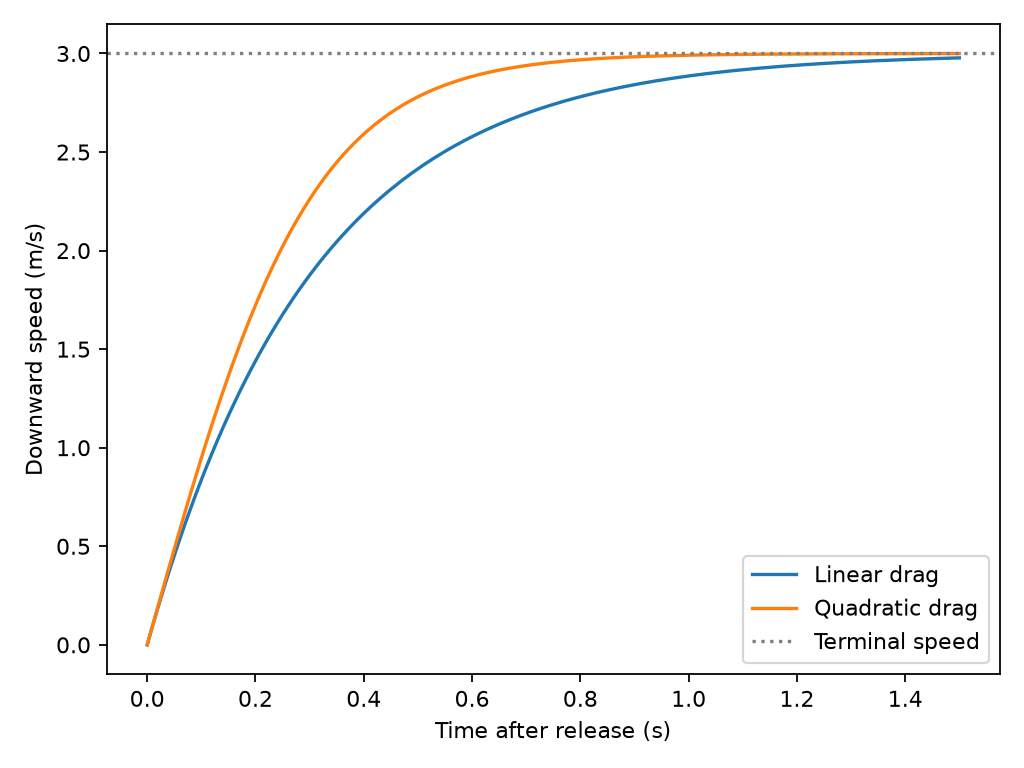

In [1]:
"""Drop a bead from rest in two media with equal terminal speeds."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.time import ClassicalRungeKutta4TimeIntegrator

g, terminal = 9.81, 3.0  # effective downward acceleration and terminal speed
step = 0.01
time = np.arange(151) * step
method = ClassicalRungeKutta4TimeIntegrator()

def rates(speed, t):
    linear, quadratic = speed
    return (g * (1 - linear / terminal),
            g * (1 - quadratic * abs(quadratic) / terminal**2))

speeds = [(0.0, 0.0)]
for t in time[:-1]:
    speeds.append(method.advance(speeds[-1], rates, step, time=t))
linear, quadratic = np.array(speeds).T
exact = terminal * np.tanh(g * time / terminal)
print(f"At 0.30 s: linear {linear[30]:.4f} m/s, quadratic {quadratic[30]:.4f} m/s")
print(f"Largest RK4 discrepancy for quadratic drag: {max(abs(exact-quadratic)):.2e} m/s")
plt.plot(time, linear, label="Linear drag")
plt.plot(time, quadratic, label="Quadratic drag")
plt.axhline(terminal, linestyle=":", color="grey", label="Terminal speed")
plt.xlabel("Time after release (s)")
plt.ylabel("Downward speed (m/s)")
plt.legend()
plt.tight_layout()
plt.savefig("physics-drag-laws.png", dpi=160)

plt.show()
